# BIRFI with NumPy

Blind IRF identification (Gómez-Sánchez *et al.*, *Biophys. Rep.* **4**, 100155, 2024).

For $t \ge m$ the IRF has finished acting, so $y(t) = B\,x(t)$: the tail of the decay, shifted to the origin, **is** the underlying decay $x$. With $x$ known, $y = h * x$ is solved for $h$ by polynomial division.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations, product

## 1 · Decay import
Crop so the window starts just before the rise (the IRF is positioned relative to `t[0]`). Background from the far tail.

240 bins, dt = 100 ps, peak = 49667 counts, background = 26.5


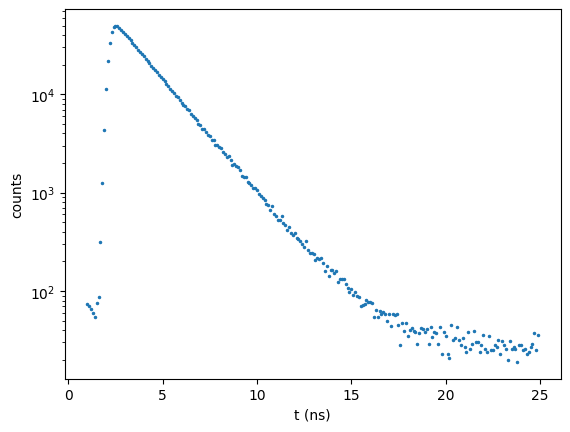

In [2]:
t, y_raw = np.loadtxt("LifeTimeHistogramCh1.csv", delimiter=",", skiprows=1, unpack=True)
keep = t >= 1.0
t, y_raw = t[keep], y_raw[keep]
dt = t[1] - t[0]

bg = np.median(y_raw[-30:])
y = y_raw - bg
print(f"{t.size} bins, dt = {dt*1e3:.0f} ps, peak = {y_raw.max():.0f} counts, background = {bg}")

plt.semilogy(t, y_raw, ".", ms=3); plt.xlabel("t (ns)"); plt.ylabel("counts"); plt.show()

## 2 · Derivative
Differentiate a **smoothed** trace. The Whittaker smoother is a low-pass filter, $H(\omega) = 1/(1+16\lambda\sin^4(\omega/2))$,
so $\lambda$ is a cutoff period: $T_c \approx 2\pi\lambda^{1/4}$ samples. Here $\lambda = 10 \Rightarrow T_c \approx 11$ samples.

In [3]:
def whittaker(y, lam):
    # argmin ||y - z||^2 + lam ||D2 z||^2   ->   (I + lam D'D) z = y
    D = np.diff(np.eye(y.size), 2, axis=0)
    return np.linalg.solve(np.eye(y.size) + lam * D.T @ D, y)

ys = whittaker(y, lam=10.0)
dy = np.gradient(ys, dt)

## 3 · Finding m
The minimum of $dy/dt$ after the peak marks the frontier between the IRF-distorted region and the exponential tail.

m = 20  ->  t_cut = 3.00 ns


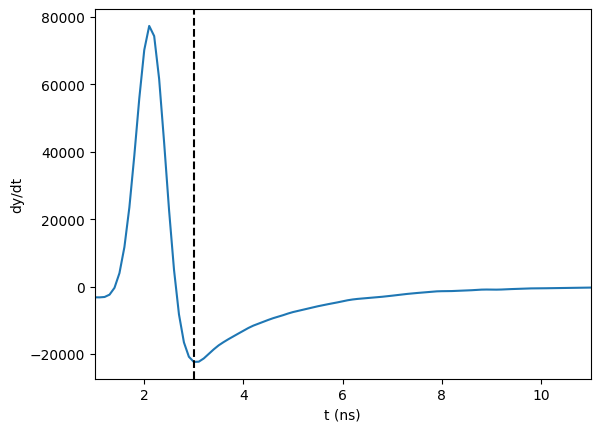

In [4]:
ipk = np.argmax(ys)
m = ipk + np.argmin(dy[ipk:])
print(f"m = {m}  ->  t_cut = {t[m]:.2f} ns")

plt.plot(t, dy); plt.axvline(t[m], ls="--", c="k")
plt.xlim(t[0], t[0] + 10); plt.xlabel("t (ns)"); plt.ylabel("dy/dt"); plt.show()

### Check · is the tail monoexponential?
Past $m$ the tail is IRF-free, $\sum_i a_i B_i e^{-t/\tau_i}$, so it can be tested directly: fit 1 vs 2 exponentials, F-test.
**Start at $m$** — a fast component is only visible there. Scan a few cuts and require *consistency*:
a real second component gives $p \approx 0$ every time with a stable $\tau_2$.

In [5]:
def chi2_exp(u, yt, w, taus):
    # amplitudes are linear: solve them exactly for fixed lifetimes (variable projection)
    E = np.exp(-u[:, None] / np.asarray(taus)[None, :])
    c = np.linalg.lstsq(E * w[:, None], yt * w, rcond=None)[0]
    return np.sum(((yt - E @ c) * w) ** 2) if np.all(c >= 0) else np.inf

def fit_exp(u, yt, w, n):
    grid = np.geomspace(0.05, 30, 60)                       # coarse grid over the lifetimes...
    chi, taus = min((chi2_exp(u, yt, w, c), c) for c in combinations(grid, n))
    f = 1.3
    for _ in range(10):                                     # ...then zoom in
        chi, taus = min((chi2_exp(u, yt, w, c), c)
                        for c in product(*[s * np.geomspace(1 / f, f, 11) for s in taus]))
        f = f ** 0.5
    return chi, np.array(taus)

end = np.flatnonzero(ys > 5e-3 * ys.max())[-1]
for c in (m, m + 2, m + 4, m + 6):
    u, yt, w = t[c:end] - t[c], y[c:end], 1 / np.sqrt(np.maximum(y_raw[c:end], 1))
    chi1, _ = fit_exp(u, yt, w, 1)
    chi2, tau2 = fit_exp(u, yt, w, 2)
    d2 = u.size - 4
    F = max((chi1 - chi2) / 2 / (chi2 / d2), 0.0)
    p = (1 + 2 * F / d2) ** (-d2 / 2)                       # exact survival function of F(2, d2)
    print(f"cut at {t[c]:.1f} ns:  F = {F:5.2f}   p = {p:.3f}   2-exp lifetimes = {np.sort(tau2).round(2)} ns")

cut at 3.0 ns:  F =  1.80   p = 0.171   2-exp lifetimes = [1.8  2.08] ns


cut at 3.2 ns:  F =  2.55   p = 0.084   2-exp lifetimes = [1.53 1.92] ns
cut at 3.4 ns:  F =  3.19   p = 0.046   2-exp lifetimes = [1.24 1.9 ] ns


cut at 3.6 ns:  F =  2.99   p = 0.056   2-exp lifetimes = [1.19 1.9 ] ns


## 4 · Shifting
The tail, re-indexed to start at $u = 0$, is $x$ up to a scalar. The boundary bin is **shared**: the IRF covers bins $0 \dots m$.

In [6]:
x = y[m:]          # shifted tail = underlying decay (up to a scalar)
L = m + 1          # IRF length = len(y) - len(x) + 1
print(f"len(y) = {y.size},  len(x) = {x.size},  IRF length = {L}")

len(y) = 240,  len(x) = 220,  IRF length = 21


## 5 · Deconvolution → IRF
Forward substitution, $h[n] = \big(y[n] - \sum_{k<n} h[k]\,x[n-k]\big)/x[0]$ — polynomial long division, i.e. MATLAB `deconv` / `np.polydiv`.

It is a differencing operation, so smooth $y$ first — but **mildly**, with a different $\lambda$ from step 2.
Rule: $T_c = 0.6 \times$ the 10–90 % rise time (a proxy for the IRF width) costs ≈ 1 % bias.

rise = 4.25 samples  ->  lambda_deconv = 0.0271
negative mass = 0.0%,  mass in last 20 % = 2.4%


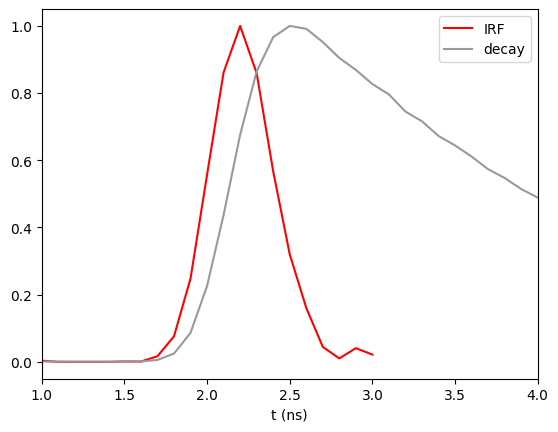

In [7]:
rise = np.ptp(np.interp([0.1, 0.9], y[:ipk + 1] / y[:ipk + 1].max(), t[:ipk + 1])) / dt
lam_deconv = (0.6 * rise / (2 * np.pi)) ** 4
yd = whittaker(y, lam_deconv)
print(f"rise = {rise:.2f} samples  ->  lambda_deconv = {lam_deconv:.4f}")

def irf_from(yd, m):
    x = yd[m:]
    h, r = np.zeros(m + 1), yd.copy()
    for n in range(m + 1):
        h[n] = r[n] / x[0]                   # next IRF sample
        r[n:n + x.size] -= h[n] * x          # remove its contribution
    return h

h = irf_from(yd, m)
assert np.allclose(h, np.polydiv(yd, yd[m:])[0])          # identical to np.polydiv

def diagnostics(h):
    neg = -h[h < 0].sum() / np.abs(h).sum()                # overshoot: surplus bins go negative
    tail = h[-max(1, h.size // 5):].sum() / h.sum()        # undershoot: IRF not back to zero
    return neg, tail

irf = np.clip(h, 0, None); irf /= irf.sum()
print("negative mass = {:.1%},  mass in last 20 % = {:.1%}".format(*diagnostics(h)))

plt.plot(t[:L], irf / irf.max(), "r", label="IRF")
plt.plot(t, y / y.max(), c="0.6", label="decay")
plt.xlim(t[0], t[m] + 1); plt.xlabel("t (ns)"); plt.legend(); plt.show()

## 6 · Lifetime
Reconvolution fit $y = A\,(\mathrm{IRF} * e^{-t/\tau}) + b$. For fixed $\tau$ the model is linear in $A, b$,
so scan $\tau$ and solve those exactly. Error bar from $\Delta\chi^2 = 1$.

In [8]:
w = 1 / np.sqrt(np.maximum(y_raw, 1))                      # Poisson weights

def chi2_tau(tau, irf):
    M = np.column_stack([np.convolve(irf, np.exp(-(t - t[0]) / tau))[:t.size], np.ones(t.size)])
    c = np.linalg.lstsq(M * w[:, None], y_raw * w, rcond=None)[0]
    return np.sum(((y_raw - M @ c) * w) ** 2), M @ c

def fit_tau(irf):
    taus = np.linspace(0.1, 10, 991)
    t0 = taus[np.argmin([chi2_tau(s, irf)[0] for s in taus])]
    taus = np.linspace(t0 - 0.02, t0 + 0.02, 2001)
    chi = np.array([chi2_tau(s, irf)[0] for s in taus])
    k = np.argmin(chi)
    inside = taus[chi <= chi[k] + 1]
    return taus[k], (inside.max() - inside.min()) / 2, chi[k] / (t.size - 3)

tau, err, chi2r = fit_tau(irf)
print(f"tau = {tau:.4f} +- {err:.4f} ns   chi2_red = {chi2r:.3f}")

tau = 1.8778 +- 0.0018 ns   chi2_red = 1.146


## 7 · Refine m
The derivative gives a *starting* $m$. The two diagnostics bracket it from opposite sides, and $\chi^2$ decides.
The spread of $\tau$ over the $m$ values that fit equally well is a systematic error — usually larger than the statistical one.

m = 17 (2.7 ns)   neg =  0.0%   tail = 10.5%   tau = 1.8933   chi2_red = 2.085


m = 18 (2.8 ns)   neg =  0.0%   tail =  4.2%   tau = 1.8914   chi2_red = 1.895


m = 19 (2.9 ns)   neg =  0.0%   tail =  5.2%   tau = 1.8835   chi2_red = 1.337


m = 20 (3.0 ns)   neg =  0.0%   tail =  2.4%   tau = 1.8778   chi2_red = 1.146


m = 21 (3.1 ns)   neg =  0.0%   tail =  2.5%   tau = 1.8681   chi2_red = 1.133


m = 22 (3.2 ns)   neg =  0.6%   tail =  1.6%   tau = 1.8681   chi2_red = 1.141


m = 23 (3.3 ns)   neg =  0.5%   tail =  1.2%   tau = 1.8613   chi2_red = 1.302


m = 24 (3.4 ns)   neg =  0.9%   tail =  0.8%   tau = 1.8617   chi2_red = 1.290


m = 25 (3.5 ns)   neg =  0.9%   tail =  1.0%   tau = 1.8552   chi2_red = 1.516

best m = 21:  tau = 1.8681 ns   chi2_red = 1.133
   statistical  +- 0.0018 ns
   systematic   +- 0.0049 ns   (spread over 3 equivalent m)


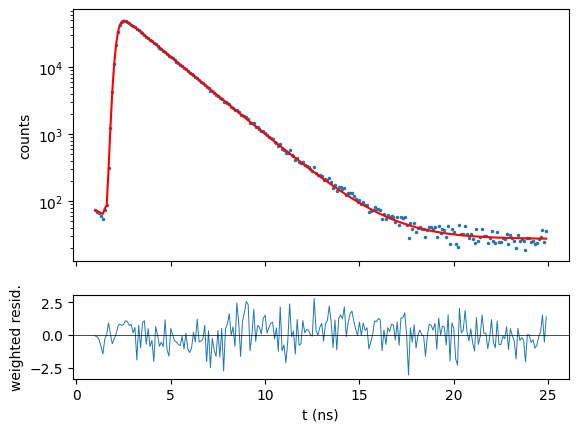

In [9]:
rows = []
for mm in range(m - 3, m + 6):
    hh = irf_from(yd, mm)
    neg, tail = diagnostics(hh)
    ir = np.clip(hh, 0, None); ir /= ir.sum()
    rows.append((mm, *fit_tau(ir), neg, tail))
    print(f"m = {mm:2d} ({t[mm]:.1f} ns)   neg = {neg:5.1%}   tail = {tail:5.1%}   "
          f"tau = {rows[-1][1]:.4f}   chi2_red = {rows[-1][3]:.3f}")

m_best, tau, err, chi2r, *_ = min(rows, key=lambda r: r[3])
irf = np.clip(irf_from(yd, m_best), 0, None); irf /= irf.sum()
_, model = chi2_tau(tau, irf)
good = [r[1] for r in rows if r[3] <= 1.05 * chi2r]          # m values fitting within 5 % in chi2
print(f"\nbest m = {m_best}:  tau = {tau:.4f} ns   chi2_red = {chi2r:.3f}")
print(f"   statistical  +- {err:.4f} ns")
print(f"   systematic   +- {np.ptp(good) / 2:.4f} ns   (spread over {len(good)} equivalent m)")

fig, (a, b) = plt.subplots(2, 1, sharex=True, height_ratios=[3, 1])
a.semilogy(t, y_raw, ".", ms=3); a.semilogy(t, model, "r"); a.set_ylabel("counts")
b.plot(t, (y_raw - model) * w, lw=0.7); b.axhline(0, c="k", lw=0.5)
b.set_xlabel("t (ns)"); b.set_ylabel("weighted resid."); plt.show()